# Parte 2b — Optimización de hiperparámetros y evaluación de generalización

**Caso B — Predicción de precios de viviendas (Ames Iowa Housing).** Este notebook continúa el notebook 02 y
cubre dos indicadores de la Evaluación Parcial N°3:

- **IE9 — Optimización de hiperparámetros:** búsqueda ampliada, comparación de métodos y justificación de cada decisión.
- **IE11 — Capacidad de generalización:** métricas por fold (media ± desviación), validación cruzada anidada,
  curvas de aprendizaje y comparación entrenamiento / validación cruzada / prueba.

Reglas de trabajo (las mismas del README, secciones 4 y 6.3):

- Mismo split de la Parte 1 (80 % / 20 %, `random_state=42`) y mismas 5 particiones de validación cruzada.
- La elección de hiperparámetros se hace **solo con validación cruzada sobre entrenamiento**.
- El conjunto de prueba se usa únicamente para **informar** (sección 5.4), nunca para decidir.
- Todo el preprocesamiento va dentro del `Pipeline`, de modo que se ajusta en cada partición (sin fuga de datos).
- La lógica reutilizable vive en `src/train.py`; este notebook la llama y explica los resultados.

**Orden de ejecución:** notebook 01 → notebook 02 → este notebook (02b). Tarda varios minutos (búsquedas y CV anidada).

In [1]:
from pathlib import Path
import sys
import time
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import cross_val_predict

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

directorio_actual = Path.cwd()
if (directorio_actual / "src").is_dir():
    ROOT = directorio_actual
elif (directorio_actual.parent / "src").is_dir():
    ROOT = directorio_actual.parent
else:
    raise FileNotFoundError("Abre el notebook desde la raíz del proyecto o desde su carpeta notebooks.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.utils import MODELS
from src.train import (
    RANDOM_STATE, cargar_datos_crudos, calcular_metricas, crear_cv, evaluar, evaluar_metas,
    construir_pipeline, construir_ridge, construir_boosting, construir_boosting_es,
    construir_ridge_robusto, referencia_mediana,
    GRILLA_RIDGE_ROBUSTO, ESPACIO_BOOSTING, SIN_RECORTE,
    buscar_grilla_con_train, buscar_aleatoria, tabla_busqueda, tabla_sensibilidad,
    metricas_por_fold, resumir_folds, cv_anidada, curva_aprendizaje, guardar_json,
)
from sklearn.base import clone

IMAGES_DIR = ROOT / "images"
IMAGES_DIR.mkdir(parents=True, exist_ok=True)
MODELS.mkdir(parents=True, exist_ok=True)

N_ITER_BOOSTING = 30   # configuraciones de la búsqueda aleatoria del boosting (5 particiones cada una)
N_ITER_ANIDADA = 12    # configuraciones por búsqueda interna en la CV anidada (3 particiones internas)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False})

## 1. Datos de entrada

Se usan los datos crudos ya limpios (`cargar_datos_crudos()`), como en el notebook 02, porque el preprocesamiento
debe ajustarse dentro de cada partición de validación cruzada. `Sale Type` y `Sale Condition` siguen excluidas
(solo se conocen al cerrar la venta).

In [2]:
X_train, X_test, y_train, y_test = cargar_datos_crudos()
cv = crear_cv()   # KFold(5, shuffle=True, random_state=42): las mismas particiones que el notebook 02

# Referencia del KPI (predice la mediana del entrenamiento)
ref = referencia_mediana(X_train, y_train)

pd.Series({"registros_entrenamiento": len(X_train), "registros_prueba": len(X_test),
           "predictores": X_train.shape[1]})

registros_entrenamiento    2344
registros_prueba            586
predictores                  77
dtype: int64

## 2. Diagnóstico: ¿por qué Ridge tenía R² = 0,19 en validación cruzada?

En la tabla del notebook 02, el Ridge muestra en validación cruzada un RMSE de 69.346 USD y un R² de 0,19, pero
en prueba un RMSE de 32.246 USD y un R² de 0,87. Una diferencia tan grande entre validación y prueba es una señal de alerta,
así que se calculan las métricas **por fold** y se buscan las viviendas con mayor error.

In [3]:
ridge_base = construir_pipeline(construir_ridge(1.0), X_train, log_objetivo=True)   # el Ridge de la Parte 2

folds_ridge_base = metricas_por_fold(ridge_base, X_train, y_train, cv)
display(folds_ridge_base[["fold", "MAE", "RMSE", "R2", "Cobertura_10"]].round(3))

# Predicciones fuera de muestra y fold al que pertenece cada vivienda
pred_ridge_base = cross_val_predict(ridge_base, X_train, y_train, cv=cv)
fold_de = np.zeros(len(X_train), dtype=int)
for k, (_, idx_val) in enumerate(cv.split(X_train), start=1):
    fold_de[idx_val] = k

errores = pd.DataFrame({
    "fold": fold_de, "SalePrice real": y_train.to_numpy(), "Predicción CV": pred_ridge_base.round(0),
    "Gr Liv Area": X_train["Gr Liv Area"].to_numpy(), "Neighborhood": X_train["Neighborhood"].to_numpy(),
}, index=X_train.index)
errores["Error absoluto"] = (errores["Predicción CV"] - errores["SalePrice real"]).abs()
display(errores.sort_values("Error absoluto", ascending=False).head(5))

grandes = pd.Series({"Viviendas con Gr Liv Area > 4.000 pies² (entrenamiento)": int((X_train["Gr Liv Area"] > 4000).sum()),
                     "Viviendas con Gr Liv Area > 4.000 pies² (prueba)": int((X_test["Gr Liv Area"] > 4000).sum())})
display(grandes)

,fold,MAE,RMSE,R2,Cobertura_10
0,1,13583.326,19276.072,0.932,0.712
1,2,13867.766,21814.024,0.915,0.727
2,3,15729.725,23268.320,0.918,0.678
3,4,14313.328,20595.762,0.930,0.710
4,5,22842.301,149226.746,-2.694,0.733


,fold,SalePrice real,Predicción CV,Gr Liv Area,Neighborhood,Error absoluto
1498,5,160000,2932023.0,5642,Edwards,2772023.0
2180,5,183850,1779196.0,5095,Edwards,1595346.0
1182,2,150000,339689.0,2944,Veenker,189689.0
2256,3,330000,181691.0,1502,GrnHill,148309.0
1640,5,392000,262106.0,1419,StoneBr,129894.0


Viviendas con Gr Liv Area > 4.000 pies² (entrenamiento)    4
Viviendas con Gr Liv Area > 4.000 pies² (prueba)           1
dtype: int64

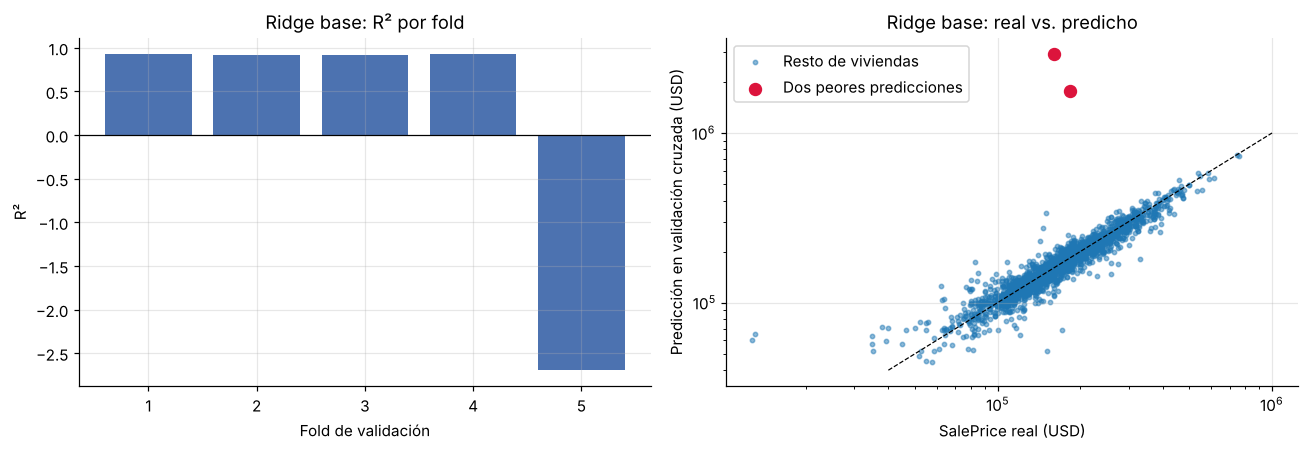

In [4]:
# Figura: R² por fold y valores reales vs. predichos (se destacan las dos peores predicciones)
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.2))

ejes[0].bar(folds_ridge_base["fold"], folds_ridge_base["R2"], color="#4C72B0")
ejes[0].axhline(0, color="k", lw=0.8)
ejes[0].set_xlabel("Fold de validación"); ejes[0].set_ylabel("R²")
ejes[0].set_title("Ridge base: R² por fold")

peores = errores["Error absoluto"].nlargest(2).index
ejes[1].scatter(errores["SalePrice real"], errores["Predicción CV"], s=8, alpha=0.5, label="Resto de viviendas")
ejes[1].scatter(errores.loc[peores, "SalePrice real"], errores.loc[peores, "Predicción CV"], s=60, color="crimson",
                label="Dos peores predicciones")
ejes[1].plot([4e4, 1e6], [4e4, 1e6], "k--", lw=0.8)
ejes[1].set_xscale("log"); ejes[1].set_yscale("log")
ejes[1].set_xlabel("SalePrice real (USD)"); ejes[1].set_ylabel("Predicción en validación cruzada (USD)")
ejes[1].set_title("Ridge base: real vs. predicho"); ejes[1].legend()
plt.tight_layout()
plt.savefig(IMAGES_DIR / "optimizacion_ridge_anomalia.png", bbox_inches="tight")
plt.show()

### Lectura del diagnóstico

- En los folds 1 a 4 el Ridge base rinde de forma estable (R² entre 0,915 y 0,932; MAE entre 13.583 y 15.730 USD).
  **El fold 5 es el problema:** R² = −2,69, RMSE = 149.227 USD y MAE = 22.842 USD.
- Las dos peores predicciones caen en ese fold y son dos viviendas de Edwards con **5.642 y 5.095 pies² de superficie habitable**,
  vendidas en 160.000 y 183.850 USD. Ridge predijo **2.932.023 y 1.779.196 USD**. Son casos atípicos conocidos del dataset de Ames:
  muy grandes pero baratos, algo que ningún modelo basado solo en la superficie puede anticipar.
- **Mecanismo.** Ridge trabaja con `log1p(SalePrice)` y es lineal: una superficie de más de 7 desviaciones estándar sobre la media suma mucho en la escala log,
  y `expm1` convierte ese exceso en millones. Un boosting no extrapola fuera del rango visto en entrenamiento, por eso no sufre este problema.
- En todo el entrenamiento hay **4 viviendas** con más de 4.000 pies² (y 1 en prueba). Los dos casos extremos quedaron en el mismo fold de validación;
  por eso el R² agrupado del notebook 02 (0,19) parecía incompatible con el de prueba (0,87): **la prueba casi no tiene viviendas de ese tipo.**
- **Consecuencia para las comparaciones:** la desventaja del Ridge en validación cruzada del notebook 02 era un artefacto de la extrapolación,
  no una debilidad general del modelo lineal. Corregirlo cambia el ranking (secciones 5.1 y 5.4).

## 3. Ridge robusto: búsqueda conjunta de `alpha` y del recorte de valores extremos

**Decisión de diseño.** El README fija el criterio de *no eliminar* viviendas solo por ser inusuales. Por eso la
corrección no quita filas: agrega al preprocesador un paso que **recorta las variables numéricas estandarizadas** a
`[-z, z]` (`recorte_z` en `construir_preprocesador`). El paso no aprende nada de los datos (sin riesgo de fuga) y
afecta solo a las variables numéricas, no a las categorías codificadas. `z` se trata como un hiperparámetro más,
elegido en validación cruzada junto con `alpha`.

| Hiperparámetro | Valores | Por qué |
|---|---|---|
| `alpha` (penalización L2) | 0,1; 0,3; 1; 3; 10; 30; 100; 300 | Escala logarítmica y rango más ancho que en el notebook 02 (0,1–100) |
| `recorte_z` | sin recorte; 5; 4; 3; 2,5; 2 | Desde "sin recorte" (Ridge original) hasta recortes agresivos |

El método es `GridSearchCV` (48 combinaciones × 5 particiones), pues el espacio es pequeño y se puede explorar completo.
El criterio es el **MAE** de validación cruzada, que es la métrica del KPI del proyecto.

In [5]:
t0 = time.time()
ridge_plantilla = construir_ridge_robusto(X_train)
busqueda_ridge = buscar_grilla_con_train(ridge_plantilla, GRILLA_RIDGE_ROBUSTO, X_train, y_train, cv)
tabla_ridge = tabla_busqueda(busqueda_ridge)
print(f"{len(tabla_ridge)} combinaciones evaluadas en {time.time() - t0:.0f} s")

mejor_ridge = {"alpha": float(tabla_ridge.loc[0, "alpha"]), "recorte_z": float(tabla_ridge.loc[0, "recorte_z"])}
print("Mejor Ridge robusto:", mejor_ridge)
display(tabla_ridge.head(10).round(1))

48 combinaciones evaluadas en 20 s
Mejor Ridge robusto: {'alpha': 30.0, 'recorte_z': 3.0}


,alpha,recorte_z,MAE_CV,MAE_CV_desv,MAE_entrenamiento,segundos_ajuste
0,30.0,3.0,14084.0,979.3,12798.6,0.0
1,10.0,3.0,14091.8,853.5,12438.2,0.0
2,30.0,2.5,14134.8,921.3,12883.7,0.0
3,10.0,2.5,14163.7,800.0,12525.8,0.0
4,10.0,4.0,14163.9,1056.6,12440.9,0.0
5,30.0,4.0,14165.8,1160.4,12831.1,0.0
6,3.0,3.0,14183.8,835.2,12114.0,0.0
7,3.0,4.0,14246.0,1025.6,12113.5,0.0
8,1.0,3.0,14258.0,945.8,11818.9,0.0
9,3.0,2.5,14267.8,741.4,12203.0,0.0


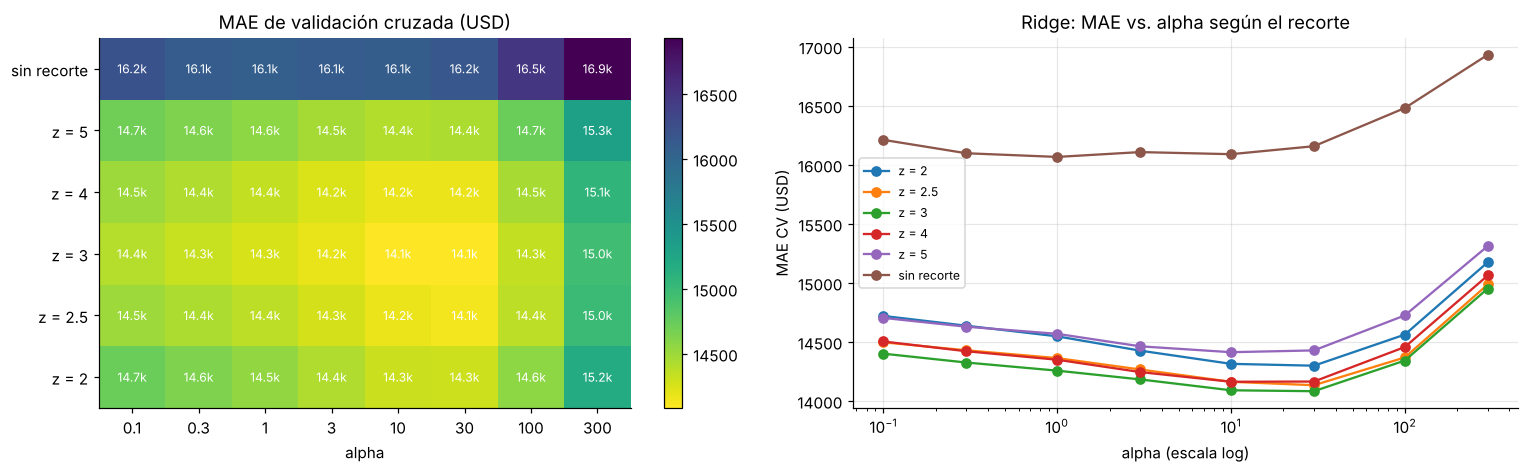

In [6]:
# Mapa de calor del MAE de CV según alpha y recorte z, y curvas MAE vs. alpha
etiqueta_z = lambda z: "sin recorte" if z >= SIN_RECORTE else f"z = {z:g}"
piv = tabla_ridge.pivot(index="recorte_z", columns="alpha", values="MAE_CV").sort_index(ascending=False)

fig, ejes = plt.subplots(1, 2, figsize=(14, 4.4))
im = ejes[0].imshow(piv.to_numpy(), cmap="viridis_r", aspect="auto")
ejes[0].set_xticks(range(len(piv.columns))); ejes[0].set_xticklabels([f"{a:g}" for a in piv.columns])
ejes[0].set_yticks(range(len(piv.index))); ejes[0].set_yticklabels([etiqueta_z(z) for z in piv.index])
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        ejes[0].text(j, i, f"{piv.iloc[i, j]/1000:.1f}k", ha="center", va="center", color="white", fontsize=8)
ejes[0].set_xlabel("alpha"); ejes[0].set_title("MAE de validación cruzada (USD)"); ejes[0].grid(False)
plt.colorbar(im, ax=ejes[0])

for z, g in tabla_ridge.groupby("recorte_z"):
    g = g.sort_values("alpha")
    ejes[1].plot(g["alpha"], g["MAE_CV"], marker="o", label=etiqueta_z(z))
ejes[1].set_xscale("log"); ejes[1].set_xlabel("alpha (escala log)"); ejes[1].set_ylabel("MAE CV (USD)")
ejes[1].set_title("Ridge: MAE vs. alpha según el recorte"); ejes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(IMAGES_DIR / "optimizacion_ridge_alpha_z.png", bbox_inches="tight")
plt.show()

### Lectura del Ridge robusto

- **Mejor configuración: `alpha = 30` y `recorte_z = 3`**, con un MAE de validación cruzada de **14.084 USD** (el Ridge base tenía 16.067).
  Es una mejora de **12,3 %** obtenida casi por completo con el recorte: el mejor MAE sin recorte (con la mejor `alpha`) es 16.067 USD, mientras que con
  `z` entre 2,5 y 4 el MAE queda entre 14.084 y 14.164 USD.
- **`z` importa mucho; `alpha` poco.** En el mapa de calor los valores de `alpha` entre 10 y 30 dan resultados casi idénticos (14.084 frente a 14.092 USD con `z = 3`).
  Esa diferencia es mucho menor que la desviación entre folds (≈1.000 USD), así que no hay base para preferir 30 sobre 10 más que el criterio de
  desempate del `GridSearchCV`. Se conserva 30 por ser el mínimo observado.
- **El recorte tiene un punto óptimo.** Un recorte demasiado agresivo (`z = 2`: 14.300 USD) empieza a perder información real, y uno suave (`z = 5`: 14.414 USD) deja pasar
  parte de la extrapolación. La región razonable es `z` entre 2,5 y 4.
- **Estabilidad de la elección.** En la CV anidada (sección 5.2) cada fold externo vuelve a elegir `alpha = 30` y `z` entre 2,5 y 4: la decisión no depende de qué viviendas se usen.
- **Decisión metodológica.** El recorte no elimina viviendas ni usa información del conjunto de prueba; se aprende dentro de cada partición solo en el sentido de que
  la estandarización previa se ajusta con el entrenamiento. Es coherente con el criterio del README de no descartar viviendas solo por ser inusuales.
- La columna `MAE_CV_desv` de las tablas de búsqueda usa la desviación poblacional (`ddof = 0`) de scikit-learn; las tablas por fold de la sección 5.1 usan `ddof = 1`.

## 4. Boosting: búsqueda aleatoria ampliada

**Por qué cambiar el método.** En el notebook 02 el `GridSearchCV` del boosting (36 combinaciones) terminó con
`learning_rate`, `max_iter`, `max_depth` y `l2_regularization` en un **extremo de la grilla**, señal de que el óptimo podía
estar fuera. Una grilla densa en 7 hiperparámetros crece de forma explosiva; `RandomizedSearchCV` explora un espacio mucho más amplio
con un presupuesto fijo (30 configuraciones × 5 particiones) y, según la literatura, cubre mejor los hiperparámetros que más importan.

| Hiperparámetro | Espacio | Por qué |
|---|---|---|
| `learning_rate` | log-uniforme 0,01 – 0,2 | Valores bajos (0,03 era el límite inferior anterior) y escala logarítmica |
| `max_iter` | 500; 800; 1.200 | Es un **tope**: se usa parada temprana (10 % interno, paciencia de 30), que elige el número real de árboles |
| `max_depth` | 3; 5; 8; sin límite | Controla la complejidad de cada árbol |
| `max_leaf_nodes` | 15; 31; 63 | No se había explorado; limita la complejidad por hoja |
| `min_samples_leaf` | 5; 10; 20; 40 | No se había explorado; regulariza hojas pequeñas |
| `l2_regularization` | 0; 1; 5; 10 | Antes solo 0 y 1 (el elegido, 1, quedaba en el extremo) |
| `loss` | error cuadrático; error absoluto | El error absoluto optimiza directamente el MAE, la métrica del KPI |

El criterio es otra vez el MAE de validación cruzada y no se usa la prueba.

In [7]:
t0 = time.time()
boost_plantilla = construir_pipeline(construir_boosting_es(), X_train)
busqueda_boost = buscar_aleatoria(boost_plantilla, ESPACIO_BOOSTING, X_train, y_train, n_iter=N_ITER_BOOSTING, cv=cv)
tabla_boost = tabla_busqueda(busqueda_boost)
print(f"{len(tabla_boost)} configuraciones evaluadas (x5 particiones) en {time.time() - t0:.0f} s")

boost_optimo = busqueda_boost.best_estimator_
arboles_usados = int(boost_optimo.named_steps["modelo"].n_iter_)
print("Mejores hiperparámetros:", {k.split("__")[-1]: v for k, v in busqueda_boost.best_params_.items()})
print("Árboles usados tras la parada temprana (modelo final, todo el entrenamiento):", arboles_usados)
display(tabla_boost.head(10).round(3))

30 configuraciones evaluadas (x5 particiones) en 551 s
Mejores hiperparámetros: {'l2_regularization': 0.0, 'learning_rate': np.float64(0.03203913722293047), 'loss': 'absolute_error', 'max_depth': 8, 'max_iter': 500, 'max_leaf_nodes': 31, 'min_samples_leaf': 5}
Árboles usados tras la parada temprana (modelo final, todo el entrenamiento): 500


,l2_regularization,learning_rate,loss,max_depth,max_iter,max_leaf_nodes,min_samples_leaf,MAE_CV,MAE_CV_desv,MAE_entrenamiento,segundos_ajuste
0,0.0,0.032,absolute_error,8,500,31,5,14707.904,1509.964,6692.968,6.080
1,10.0,0.054,absolute_error,5,500,63,20,14753.738,1401.874,8868.973,2.687
2,1.0,0.038,absolute_error,5,800,63,40,14765.608,1307.270,9889.795,3.541
3,10.0,0.027,absolute_error,8,1200,31,40,14957.081,1362.043,9265.181,6.457
4,5.0,0.017,squared_error,sin límite,800,31,10,15035.888,1211.999,7560.026,6.525
5,10.0,0.112,absolute_error,3,1200,31,5,15125.126,1166.061,8962.389,1.587
6,0.0,0.089,absolute_error,5,1200,63,5,15149.822,1532.309,7044.829,2.138
7,1.0,0.019,absolute_error,5,500,63,10,15159.673,1237.342,9610.118,3.667
8,5.0,0.109,squared_error,8,500,15,20,15183.524,1194.414,9450.804,0.817
9,10.0,0.062,squared_error,3,500,63,5,15188.730,1630.731,10365.161,1.172


,hiperparametro,valor,n,MAE_CV_medio,MAE_CV_minimo
0,learning_rate,"(0.009500000000000001, 0.0169]",8,15466.4,15035.9
1,learning_rate,"(0.0169, 0.0353]",7,15216.0,14707.9
2,learning_rate,"(0.0353, 0.0875]",7,15203.6,14753.7
3,learning_rate,"(0.0875, 0.183]",8,15338.3,15125.1
4,max_iter,1200,8,15257.1,14957.1
5,max_iter,500,15,15351.7,14707.9
6,max_iter,800,7,15291.8,14765.6
7,max_depth,3,5,15420.1,15125.1
8,max_depth,5,8,15230.8,14753.7
9,max_depth,8,9,15330.4,14707.9


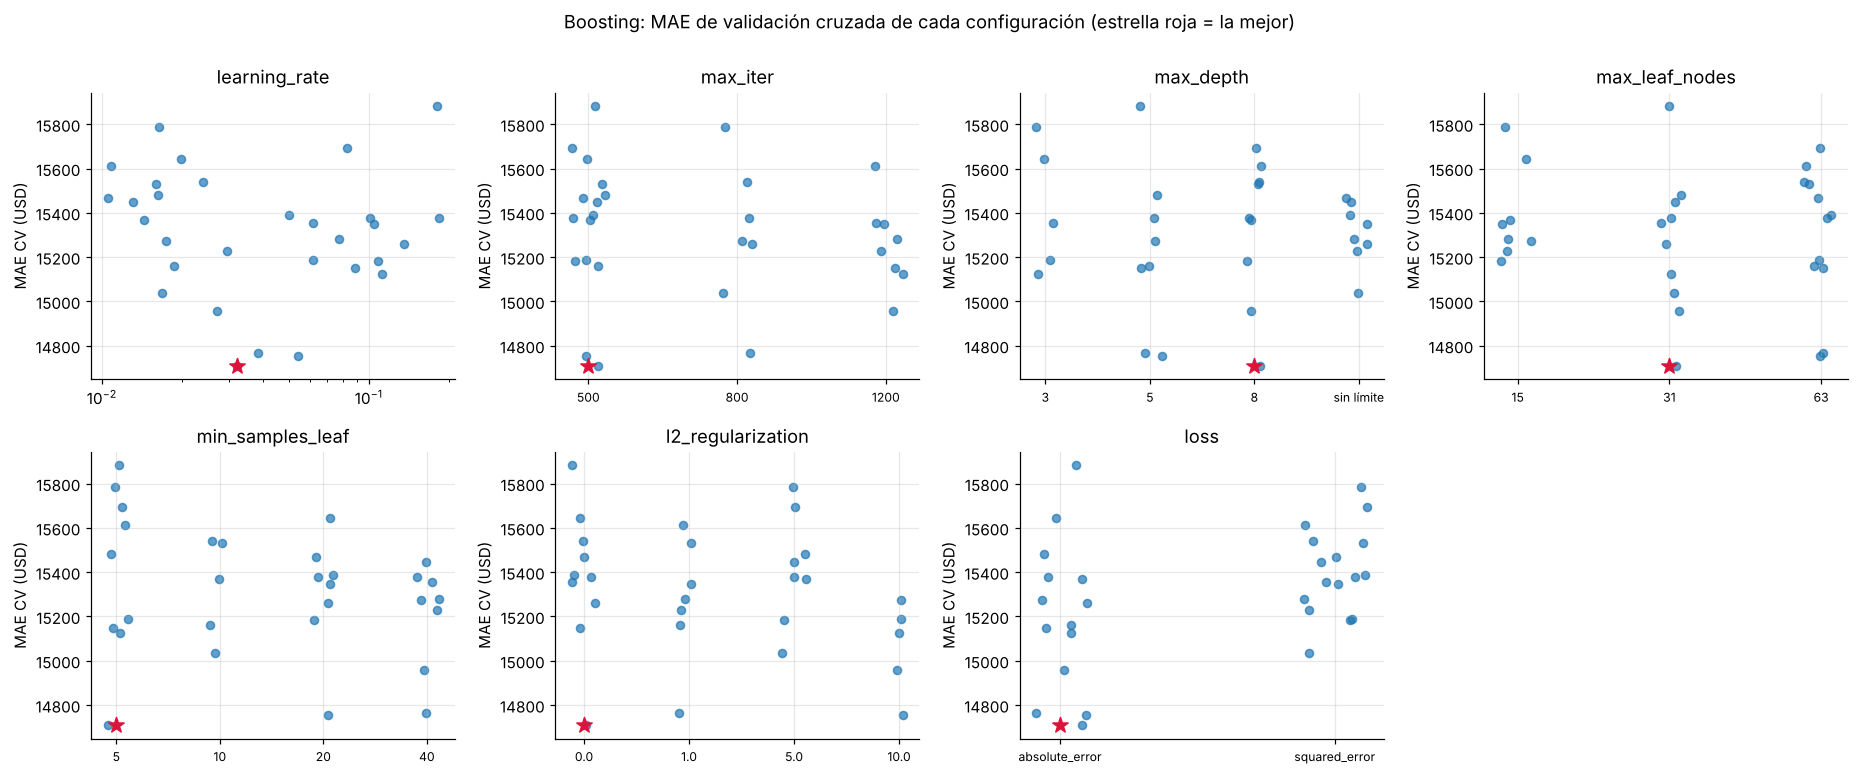

In [8]:
# Sensibilidad: cuánto cambia el MAE según cada hiperparámetro
parametros_boost = ["learning_rate", "max_iter", "max_depth", "max_leaf_nodes",
                    "min_samples_leaf", "l2_regularization", "loss"]
sensibilidad = tabla_sensibilidad(tabla_boost, parametros_boost)
display(sensibilidad.round(1))

fig, ejes = plt.subplots(2, 4, figsize=(17, 7))
ejes = ejes.ravel()
rng = np.random.default_rng(RANDOM_STATE)
es_num = lambda v: v.replace(".", "", 1).isdigit()
for ax, par in zip(ejes, parametros_boost):
    x = tabla_boost[par]
    if par == "learning_rate":
        ax.scatter(x, tabla_boost["MAE_CV"], s=28, alpha=0.7)
        ax.scatter(x.iloc[[0]], tabla_boost["MAE_CV"].iloc[[0]], s=110, color="crimson", marker="*", zorder=3)
        ax.set_xscale("log")
    else:
        cats = sorted(x.astype(str).unique(), key=lambda v: (not es_num(v), float(v) if es_num(v) else 0.0, v))
        pos = x.astype(str).map({c: i for i, c in enumerate(cats)}).to_numpy(dtype=float)
        ax.scatter(pos + rng.uniform(-0.12, 0.12, len(pos)), tabla_boost["MAE_CV"], s=28, alpha=0.7)
        ax.scatter(pos[0], tabla_boost["MAE_CV"].iloc[0], s=110, color="crimson", marker="*", zorder=3)
        ax.set_xticks(range(len(cats))); ax.set_xticklabels(cats, fontsize=8)
    ax.set_title(par); ax.set_ylabel("MAE CV (USD)")
ejes[-1].axis("off")
plt.suptitle("Boosting: MAE de validación cruzada de cada configuración (estrella roja = la mejor)", y=1.0)
plt.tight_layout()
plt.savefig(IMAGES_DIR / "optimizacion_boosting_sensibilidad.png", bbox_inches="tight")
plt.show()

### Lectura de la búsqueda del boosting

- **Resultado honesto: la búsqueda ampliada no mejoró el error de validación cruzada.** Las 30 configuraciones dieron un MAE entre 14.708 y 15.884 USD
  (mediana 15.352). La mejor (14.708 USD) queda **72 USD por encima** de la configuración de la grilla original (14.636 USD, notebook 02) y
  a 209 USD de la configuración por defecto (14.917 USD). Las diferencias por fold entre ambas van de −755 a +747 USD: están dentro del ruido.
- **Lectura:** el boosting está en una meseta de ≈ 14.6–14.7 mil USD. Pasar de una grilla de 36 combinaciones en 4 hiperparámetros a 30 muestras de un espacio de 7 hiperparámetros confirma que el óptimo de la grilla
  original no estaba muy lejos; el hiperparámetro mal explorado no era la limitación principal.
- **Mejor configuración:** `loss = absolute_error`, `learning_rate = 0,032`, `max_depth = 8`, `max_leaf_nodes = 31`, `min_samples_leaf = 5`, `l2_regularization = 0`, tope de 500 iteraciones.
- **Qué se aprende de la sensibilidad** (con 30 puntos es solo orientativa):
  - `loss`: las configuraciones con error absoluto promedian 15.208 USD frente a 15.404 con error cuadrático, y las cuatro mejores usan error absoluto.
    Tiene sentido: optimiza directamente el MAE, que es la métrica del KPI.
  - `max_depth = 3` es el peor valor (15.420 USD de media): árboles demasiado simples no bastan.
  - Más regularización ayuda levemente en promedio (`l2 = 10`: 15.060 USD; `min_samples_leaf = 40`: 15.211 USD), pero el mejor modelo individual usa poca regularización.
    Los efectos son pequeños frente a la dispersión entre folds, así que no se interpretan como reglas.
- **Advertencias sobre el óptimo encontrado:**
  1. Usó las **500 iteraciones completas**: la parada temprana no se activó, es decir, el tope de `max_iter` fue limitante para ese modelo (500 era además el valor más bajo permitido).
  2. `l2_regularization = 0` y `min_samples_leaf = 5` son los valores **extremos** de sus rangos; un rango más amplio podría moverlos.
  3. La brecha entre el MAE de entrenamiento (6.693 USD) y el de validación (14.708 USD) sigue siendo grande: la optimización no eliminó el sobreajuste (sección 5.3).
- **Decisión.** Siguiendo el criterio fijado de antemano (menor MAE de validación cruzada), la configuración de la grilla original sigue siendo marginalmente la mejor.
  Se entregan **ambas** a la Persona 2 como componentes posibles de ensamble (`models/best_params.json`).
  El hecho de que la nueva configuración rinda mejor en prueba (sección 5.4) **no se usa para decidir**.

## 5. Evaluación de la capacidad de generalización

### 5.1. Métricas por fold (media ± desviación)

Se comparan cinco modelos con las **mismas particiones**. Para cada uno se ajusta el pipeline completo en cada fold
y se miden las métricas en el fold de validación; también se registra el MAE de entrenamiento para ver el sobreajuste.
Los modelos son: Ridge base y boosting con la configuración de la Parte 2 (puntos de partida), y las dos versiones optimizadas aquí.

*Nota:* esta media por fold difiere levemente del MAE "agrupado" del notebook 02, que juntaba las predicciones de todos los folds antes de calcular.

In [9]:
modelos_cv = {
    "Ridge base (Parte 2)": ridge_base,
    "Ridge robusto (alpha + z)": busqueda_ridge.best_estimator_,
    "Boosting por defecto": construir_pipeline(construir_boosting(), X_train),
    "Boosting grilla original (Parte 2)": construir_pipeline(
        construir_boosting(learning_rate=0.03, max_depth=None, max_iter=400, l2_regularization=1.0), X_train),
    "Boosting búsqueda ampliada": boost_optimo,
}

folds = {}
for nombre, estimador in modelos_cv.items():
    t = metricas_por_fold(estimador, X_train, y_train, cv)
    t.insert(0, "modelo", nombre)
    folds[nombre] = t
tabla_folds = pd.concat(folds.values(), ignore_index=True)
resumen_cv = pd.DataFrame({n: resumir_folds(t.drop(columns="modelo")) for n, t in folds.items()}).T

presentacion = pd.DataFrame({
    "MAE (USD)": resumen_cv.apply(lambda f: f"{f['MAE_media']:,.0f} ± {f['MAE_desv']:,.0f}", axis=1),
    "RMSE (USD)": resumen_cv.apply(lambda f: f"{f['RMSE_media']:,.0f} ± {f['RMSE_desv']:,.0f}", axis=1),
    "R²": resumen_cv.apply(lambda f: f"{f['R2_media']:.3f} ± {f['R2_desv']:.3f}", axis=1),
    "Cobertura ±10 %": resumen_cv.apply(lambda f: f"{f['Cobertura_10_media']:.1%} ± {f['Cobertura_10_desv']:.1%}", axis=1),
    "MAE entrenamiento (USD)": resumen_cv["MAE_entrenamiento_media"].round(0).astype(int),
})
display(presentacion)

,MAE (USD),RMSE (USD),R²,Cobertura ±10 %,MAE entrenamiento (USD)
Ridge base (Parte 2),"16,067 ± 3,876","46,836 ± 57,257",0.200 ± 1.618,71.2% ± 2.1%,12172
Ridge robusto (alpha + z),"14,084 ± 1,095","24,099 ± 8,563",0.893 ± 0.082,73.6% ± 1.8%,12799
Boosting por defecto,"14,917 ± 1,449","24,662 ± 5,703",0.893 ± 0.049,72.2% ± 1.9%,6186
Boosting grilla original (Parte 2),"14,636 ± 1,429","24,486 ± 5,642",0.895 ± 0.049,73.2% ± 2.0%,5554
Boosting búsqueda ampliada,"14,708 ± 1,688","25,594 ± 6,334",0.885 ± 0.055,73.6% ± 2.1%,6693


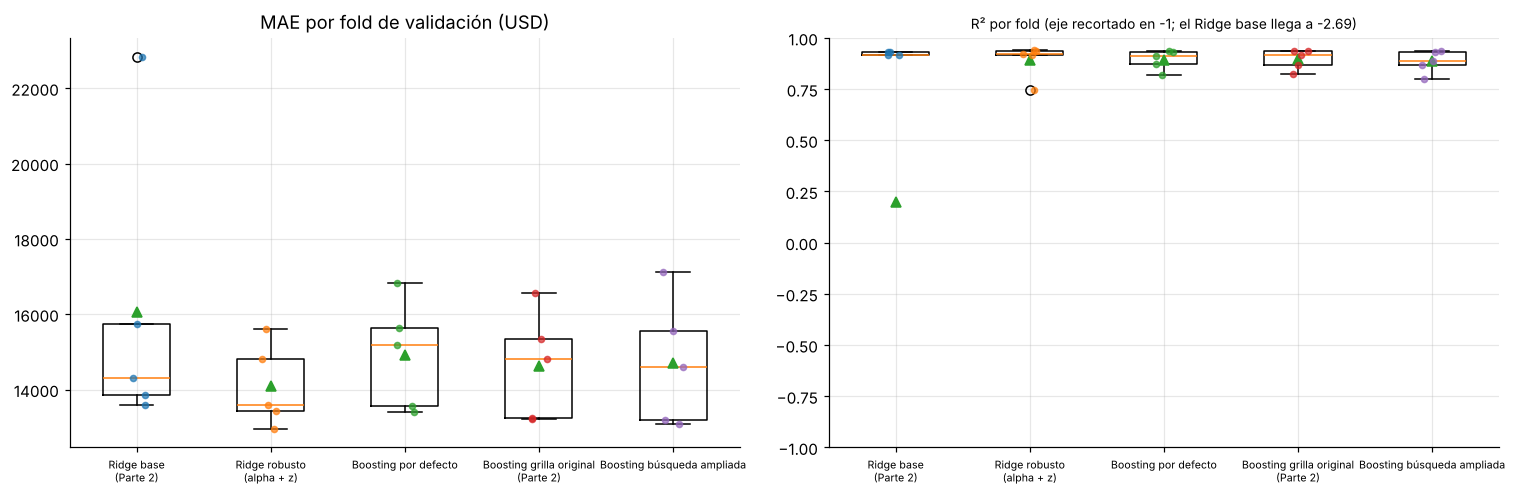

In [10]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 4.6))
nombres = list(folds)
for ax, metrica, titulo in zip(ejes, ["MAE", "R2"], ["MAE por fold de validación (USD)", "R² por fold de validación"]):
    datos = [folds[n][metrica].to_numpy() for n in nombres]
    ax.boxplot(datos, tick_labels=[n.replace(" (", "\n(") for n in nombres], showmeans=True)
    for i, d in enumerate(datos, start=1):
        ax.scatter(np.full(len(d), i) + rng.uniform(-0.08, 0.08, len(d)), d, s=16, alpha=0.7, zorder=3)
    ax.set_title(titulo); ax.tick_params(axis="x", labelsize=7)
ejes[1].set_ylim(-1, 1)   # el Ridge base tiene un fold por debajo de -1 (se anota en el título)
ejes[1].set_title("R² por fold (eje recortado en -1; el Ridge base llega a "
                  f"{folds['Ridge base (Parte 2)']['R2'].min():.2f})", fontsize=9)
plt.tight_layout()
plt.savefig(IMAGES_DIR / "validacion_folds_mae.png", bbox_inches="tight")
plt.show()

### Lectura de las métricas por fold

- **El ranking cambia respecto del notebook 02.** Con el Ridge corregido, el menor MAE de validación cruzada es el del **Ridge robusto (14.084 ± 1.095 USD)**,
  por delante de la grilla original del boosting (14.636 ± 1.429) y del boosting ampliado (14.708 ± 1.688). Antes el boosting aparecía ganando por ≈ 1.400 USD; ese margen era el artefacto de la sección 2.
- **Pero la ventaja no es concluyente.** La diferencia pareada fold a fold entre Ridge robusto y boosting original es −552 USD en promedio con desviación de 797 USD
  (Ridge mejor en 3 folds, empate en 1 y peor en 1). Con solo 5 folds no se puede afirmar que uno supere al otro; la prueba de significancia queda para la etapa de selección.
- **Estabilidad.** El Ridge robusto es el más estable entre folds (desviación del MAE 1.095 USD frente a 3.876 del Ridge base y 1.429 a 1.688 de los boosting).
  Su peor fold (15.613 USD) es menor que el peor fold de cualquier boosting (16.563 a 17.111 USD).
- **RMSE.** En validación cruzada el Ridge robusto ya no comete errores grandes peores que el boosting (RMSE 24.099 frente a 24.486 – 25.594 USD). El argumento del README de que
  «el boosting comete menos errores grandes» dependía de la extrapolación del Ridge sin corregir (y de la prueba, que casi no contiene viviendas de ese tipo).
- **Cobertura ±10 %:** los modelos corregidos y los boosting quedan entre 72 % y 74 % en validación; todos sobre la meta de 70 %.
- **Sobreajuste (MAE de entrenamiento).** El Ridge robusto tiene 12.823 USD de entrenamiento frente a 14.084 de validación (razón 1,10). Los boosting tienen 6.2–6.8 mil USD de entrenamiento y
  14.6–14.9 mil de validación (razón > 2): aprenden mucho del entrenamiento que no generaliza.

### 5.2. Validación cruzada anidada

Cuando los mismos datos eligen los hiperparámetros y estiman el error, el MAE de la mejor configuración es **optimista**.
La CV anidada lo corrige: en cada uno de los 5 folds externos se repite *toda* la búsqueda usando solo el resto de los datos
(con 3 particiones internas), y el fold externo se evalúa una única vez con la configuración ganadora de ese fold.
La diferencia entre el MAE externo y el MAE de la mejor configuración en la búsqueda mide cuánto optimismo había.

- **Ridge robusto:** misma grilla de la sección 3 (alpha × z).
- **Boosting:** misma búsqueda aleatoria de la sección 4, con 12 configuraciones por fold externo (presupuesto menor para que sea viable).

In [11]:
t0 = time.time()
anidada_ridge = cv_anidada(ridge_plantilla, GRILLA_RIDGE_ROBUSTO, X_train, y_train, n_iter=None, splits_internos=3, cv_externo=cv)
print(f"Ridge anidada: {time.time() - t0:.0f} s")
t0 = time.time()
anidada_boost = cv_anidada(boost_plantilla, ESPACIO_BOOSTING, X_train, y_train, n_iter=N_ITER_ANIDADA, splits_internos=3, cv_externo=cv)
print(f"Boosting anidada: {time.time() - t0:.0f} s")

mae_no_anidado = {
    "Ridge robusto (alpha + z)": float(tabla_ridge.loc[0, "MAE_CV"]),
    "Boosting búsqueda ampliada": float(tabla_boost.loc[0, "MAE_CV"]),
}
comparacion_anidada = pd.DataFrame({
    "MAE búsqueda (no anidado)": mae_no_anidado,
    "MAE externo anidado (media)": {"Ridge robusto (alpha + z)": anidada_ridge["MAE_externo"].mean(),
                                    "Boosting búsqueda ampliada": anidada_boost["MAE_externo"].mean()},
    "Desv. folds externos": {"Ridge robusto (alpha + z)": anidada_ridge["MAE_externo"].std(ddof=1),
                             "Boosting búsqueda ampliada": anidada_boost["MAE_externo"].std(ddof=1)},
})
comparacion_anidada["Optimismo (USD)"] = comparacion_anidada["MAE externo anidado (media)"] - comparacion_anidada["MAE búsqueda (no anidado)"]
display(comparacion_anidada.round(0))
display(anidada_boost[["fold_externo", "MAE_externo", "MAE_interno_optimista", "mejores_hiperparametros"]].round(0))

Ridge anidada: 37 s


Boosting anidada: 438 s


,MAE búsqueda (no anidado),MAE externo anidado (media),Desv. folds externos,Optimismo (USD)
Ridge robusto (alpha + z),14084.0,14250.0,1284.0,166.0
Boosting búsqueda ampliada,14708.0,14884.0,1623.0,176.0


,fold_externo,MAE_externo,MAE_interno_optimista,mejores_hiperparametros
0,1,12680.0,15859.0,"{""modelo__l2_regularization"": 1.0, ""modelo__le..."
1,2,15538.0,15652.0,"{""modelo__l2_regularization"": 5.0, ""modelo__le..."
2,3,15503.0,15297.0,"{""modelo__l2_regularization"": 1.0, ""modelo__le..."
3,4,13860.0,15611.0,"{""modelo__l2_regularization"": 1.0, ""modelo__le..."
4,5,16840.0,14943.0,"{""modelo__l2_regularization"": 1.0, ""modelo__le..."


### Lectura de la validación cruzada anidada

- **El optimismo existe pero es pequeño y similar en ambos modelos:** el MAE externo (no sesgado por la búsqueda) es 14.250 USD para el Ridge robusto
  (frente a 14.084 de la búsqueda: **+166 USD, 1,2 %**) y 14.884 USD para el boosting (frente a 14.708: **+176 USD, 1,2 %**).
  La limitación del README («el MAE de validación puede ser levemente optimista») queda así cuantificada: del orden de 170 USD.
- **El ranking se mantiene:** Ridge robusto 14.250 ± 1.284 USD frente a boosting 14.884 ± 1.623 USD. Sigue sin ser una diferencia concluyente dada la desviación entre folds.
- **Estabilidad de la elección de hiperparámetros.** El Ridge elige siempre `alpha = 30` y un `z` entre 2,5 y 4 (3 combinaciones distintas en 5 folds).
  El boosting elige 3 configuraciones distintas en 5 folds, tres de ellas idénticas (`learning_rate ≈ 0,038`, profundidad 5, 63 hojas, error absoluto): la preferencia por `loss = absolute_error` es consistente.
- Las columnas `MAE_interno_optimista` (error de las particiones internas de 3 folds) no son comparables con el MAE de 5 folds, porque cada partición interna entrena con menos datos.
- **Salvedad:** la búsqueda interna del boosting usó 12 configuraciones por fold (la búsqueda principal usó 30), por lo que su optimismo medido es el de un presupuesto de búsqueda menor.

### 5.3. Curvas de aprendizaje

Se mide el MAE de entrenamiento y de validación con 20 %, 40 %, 60 %, 80 % y 100 % de los datos de cada partición de entrenamiento.
Si la curva de validación sigue bajando al sumar datos, más datos ayudarían; una brecha grande entre ambas curvas indica sobreajuste.

Curvas de aprendizaje: 112 s


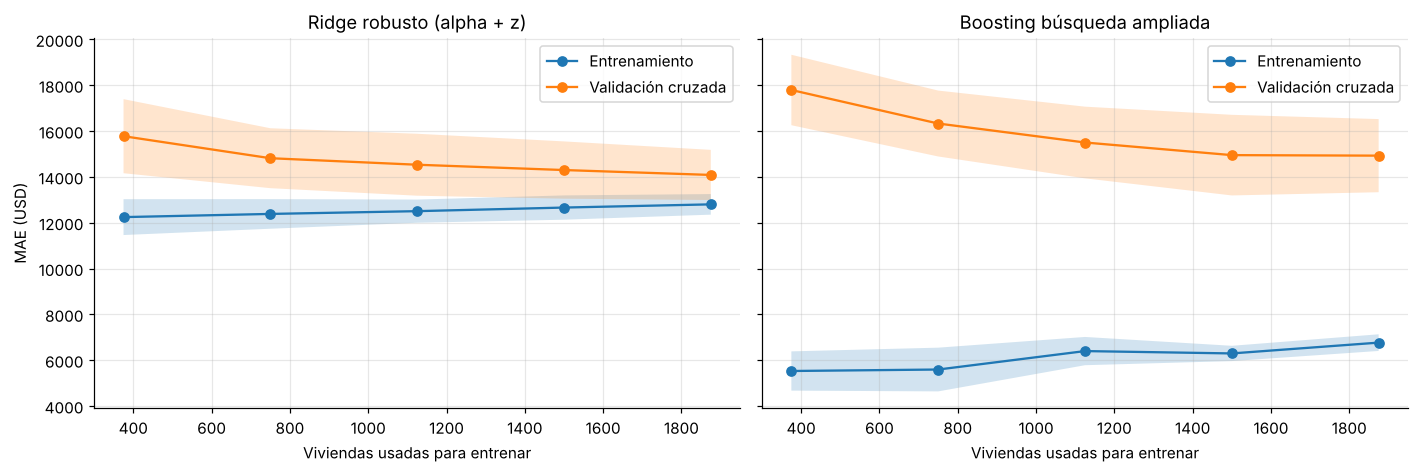

,modelo,n_entrenamiento,MAE_entrenamiento,MAE_entrenamiento_desv,MAE_validacion,MAE_validacion_desv
0,Ridge robusto (alpha + z),375,12243.0,783.0,15775.0,1617.0
1,Ridge robusto (alpha + z),750,12382.0,646.0,14814.0,1308.0
2,Ridge robusto (alpha + z),1125,12503.0,506.0,14529.0,1352.0
3,Ridge robusto (alpha + z),1500,12660.0,530.0,14298.0,1250.0
4,Ridge robusto (alpha + z),1875,12800.0,450.0,14084.0,1095.0
5,Boosting búsqueda ampliada,375,5526.0,857.0,17792.0,1538.0
6,Boosting búsqueda ampliada,750,5590.0,954.0,16328.0,1438.0
7,Boosting búsqueda ampliada,1125,6396.0,617.0,15500.0,1564.0
8,Boosting búsqueda ampliada,1500,6293.0,333.0,14949.0,1760.0
9,Boosting búsqueda ampliada,1875,6765.0,364.0,14926.0,1596.0


In [12]:
t0 = time.time()
curvas = {
    "Ridge robusto (alpha + z)": curva_aprendizaje(busqueda_ridge.best_estimator_, X_train, y_train, cv),
    "Boosting búsqueda ampliada": curva_aprendizaje(boost_optimo, X_train, y_train, cv),
}
print(f"Curvas de aprendizaje: {time.time() - t0:.0f} s")

fig, ejes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
for ax, (nombre, c) in zip(ejes, curvas.items()):
    ax.plot(c["n_entrenamiento"], c["MAE_entrenamiento"], marker="o", label="Entrenamiento")
    ax.fill_between(c["n_entrenamiento"], c["MAE_entrenamiento"] - c["MAE_entrenamiento_desv"],
                    c["MAE_entrenamiento"] + c["MAE_entrenamiento_desv"], alpha=0.2)
    ax.plot(c["n_entrenamiento"], c["MAE_validacion"], marker="o", label="Validación cruzada")
    ax.fill_between(c["n_entrenamiento"], c["MAE_validacion"] - c["MAE_validacion_desv"],
                    c["MAE_validacion"] + c["MAE_validacion_desv"], alpha=0.2)
    ax.set_title(nombre); ax.set_xlabel("Viviendas usadas para entrenar"); ax.legend()
ejes[0].set_ylabel("MAE (USD)")
plt.tight_layout()
plt.savefig(IMAGES_DIR / "validacion_curvas_aprendizaje.png", bbox_inches="tight")
plt.show()

display(pd.concat({n: c.round(0) for n, c in curvas.items()}, names=["modelo"]).droplevel(1).reset_index())

### Lectura de las curvas de aprendizaje

- **Ridge robusto: poco sobreajuste, limitado por su capacidad.** El error de entrenamiento sube de 12.243 a 12.800 USD y el de validación baja de 15.775 a 14.084 USD al pasar de 375 a 1.875 viviendas;
  la brecha se reduce de 3.532 a 1.284 USD. Entre 1.500 y 1.875 viviendas la validación aún baja (−214 USD): más datos ayudarían un poco, pero la curva se aplana.
- **Boosting ampliado: sobreajuste claro.** El entrenamiento se mantiene en 5.5–6.8 mil USD mientras la validación baja de 17.792 a 14.926 USD; la brecha final es de ≈ 8.200 USD.
  En el último tramo (1.500 → 1.875 viviendas) la validación casi no cambia (−23 USD): **más datos del mismo tipo no resolverían el sobreajuste**.
- **Implicación.** Para el boosting, el camino de mejora es reducir la varianza (regularización, promediar modelos), no recoger más datos. Esto apoya la etapa de ensambles con bagging y combinación de modelos.
- Las curvas usan su propio barajado de particiones, por lo que sus valores finales (14.084 y 14.926 USD) difieren levemente de los de la sección 5.1 (14.084 y 14.708 USD).

### 5.4. Entrenamiento vs. validación cruzada vs. prueba

Cada modelo se ajusta con **todo** el entrenamiento y se mide en entrenamiento y en prueba. Con la media de los folds de la sección 5.1
queda una tabla de tres columnas por modelo. **La prueba solo informa; no se usó para ninguna decisión de este notebook.**

In [13]:
mae_ref_test = evaluar(ref, X_test, y_test)["MAE"]

modelos_finales, filas = {}, []
for nombre, estimador in modelos_cv.items():
    ajustado = clone(estimador).fit(X_train, y_train)
    modelos_finales[nombre] = ajustado
    m_ent, m_pru = evaluar(ajustado, X_train, y_train), evaluar(ajustado, X_test, y_test)
    metas = evaluar_metas(m_pru, mae_ref_test)
    filas.append({
        "modelo": nombre,
        "MAE_entrenamiento": m_ent["MAE"], "MAE_CV_media": resumen_cv.loc[nombre, "MAE_media"],
        "MAE_CV_desv": resumen_cv.loc[nombre, "MAE_desv"], "MAE_prueba": m_pru["MAE"],
        "RMSE_CV_media": resumen_cv.loc[nombre, "RMSE_media"], "RMSE_prueba": m_pru["RMSE"],
        "R2_CV_media": resumen_cv.loc[nombre, "R2_media"], "R2_prueba": m_pru["R2"],
        "Cobertura10_CV_media": resumen_cv.loc[nombre, "Cobertura_10_media"], "Cobertura10_prueba": m_pru["Cobertura_10"],
        "Mejora_MAE_prueba_vs_mediana": metas["Mejora_MAE"],
        "Cumple_meta_cobertura": metas["Cumple_cobertura"], "Cumple_meta_mejora": metas["Cumple_mejora"],
    })
resultados_optimizacion = pd.DataFrame(filas)
resultados_optimizacion["Brecha_prueba_menos_CV"] = resultados_optimizacion["MAE_prueba"] - resultados_optimizacion["MAE_CV_media"]
resultados_optimizacion["Razon_CV_sobre_entrenamiento"] = resultados_optimizacion["MAE_CV_media"] / resultados_optimizacion["MAE_entrenamiento"]

display(resultados_optimizacion[["modelo", "MAE_entrenamiento", "MAE_CV_media", "MAE_prueba", "RMSE_prueba", "R2_prueba",
                                 "Cobertura10_prueba", "Razon_CV_sobre_entrenamiento"]].round(3))

# Comprobación de reproducibilidad contra la tabla del notebook 02
previo = pd.read_csv(MODELS / "results_supervised.csv").set_index("modelo")
for nombre_nuevo, nombre_previo in [("Ridge base (Parte 2)", "Ridge base"), ("Boosting grilla original (Parte 2)", "Boosting ajustado")]:
    nuevo = resultados_optimizacion.set_index("modelo").loc[nombre_nuevo, "MAE_prueba"]
    antiguo = previo.loc[nombre_previo, "MAE_prueba"]
    estado = "coincide" if abs(nuevo - antiguo) < 1 else "NO COINCIDE (revisar versiones)"
    print(f"{nombre_nuevo}: MAE prueba {nuevo:,.0f} vs. notebook 02 {antiguo:,.0f} -> {estado}")

,modelo,MAE_entrenamiento,MAE_CV_media,MAE_prueba,RMSE_prueba,R2_prueba,Cobertura10_prueba,Razon_CV_sobre_entrenamiento
0,Ridge base (Parte 2),12316.503,16067.289,14940.413,32245.570,0.870,0.751,1.305
1,Ridge robusto (alpha + z),12822.774,14084.007,14085.894,27557.826,0.905,0.771,1.098
2,Boosting por defecto,6703.440,14917.469,15623.869,27026.956,0.909,0.742,2.225
3,Boosting grilla original (Parte 2),6179.015,14635.747,15349.592,27284.701,0.907,0.747,2.369
4,Boosting búsqueda ampliada,6837.946,14707.904,13386.729,24046.915,0.928,0.778,2.151


Ridge base (Parte 2): MAE prueba 14,940 vs. notebook 02 14,940 -> coincide
Boosting grilla original (Parte 2): MAE prueba 15,350 vs. notebook 02 15,350 -> coincide


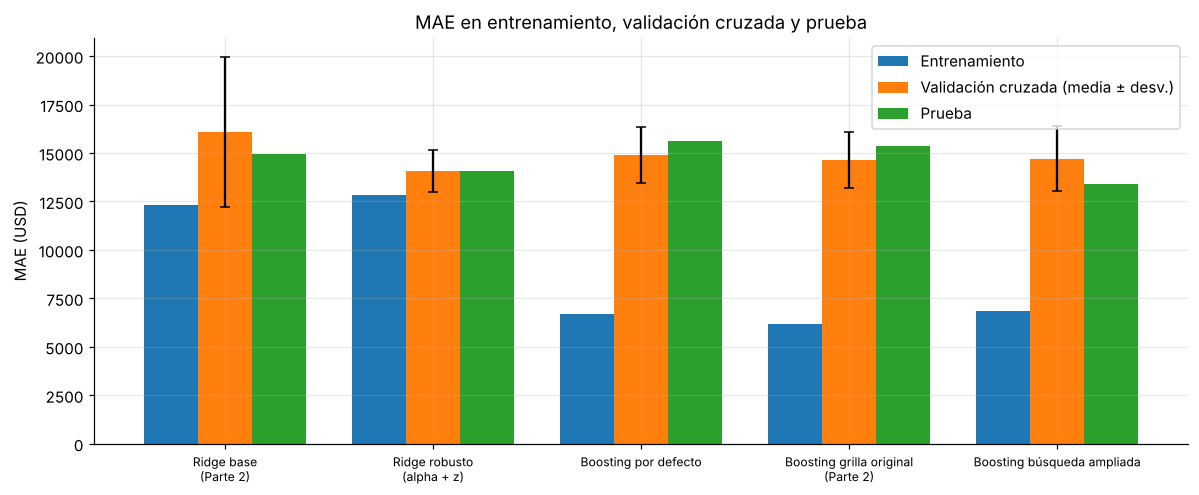

In [14]:
fig, ax = plt.subplots(figsize=(11, 4.6))
x = np.arange(len(resultados_optimizacion))
ancho = 0.26
ax.bar(x - ancho, resultados_optimizacion["MAE_entrenamiento"], ancho, label="Entrenamiento")
ax.bar(x, resultados_optimizacion["MAE_CV_media"], ancho, yerr=resultados_optimizacion["MAE_CV_desv"], capsize=3, label="Validación cruzada (media ± desv.)")
ax.bar(x + ancho, resultados_optimizacion["MAE_prueba"], ancho, label="Prueba")
ax.set_xticks(x); ax.set_xticklabels([n.replace(" (", "\n(") for n in resultados_optimizacion["modelo"]], fontsize=8)
ax.set_ylabel("MAE (USD)"); ax.set_title("MAE en entrenamiento, validación cruzada y prueba"); ax.legend()
plt.tight_layout()
plt.savefig(IMAGES_DIR / "validacion_train_cv_prueba.png", bbox_inches="tight")
plt.show()

### Lectura de entrenamiento vs. validación cruzada vs. prueba

| Modelo | MAE entrenamiento | MAE CV (media) | MAE prueba |
|---|---:|---:|---:|
| Ridge base (Parte 2) | 12.317 | 16.067 | 14.940 |
| Ridge robusto (alpha + z) | 12.823 | 14.084 | 14.086 |
| Boosting por defecto | 6.703 | 14.917 | 15.624 |
| Boosting grilla original (Parte 2) | 6.179 | 14.636 | 15.350 |
| Boosting búsqueda ampliada | 6.838 | 14.708 | 13.387 |

- **Ridge robusto: el más consistente.** Entrenamiento, validación y prueba están a ≈ 1.300 USD o menos entre sí (14.084 en CV y 14.086 en prueba).
  Su desempeño en prueba confirma lo medido en validación: la corrección no «sobreajusta» a los datos de entrenamiento.
- **Boostings: sobreajuste moderado pero estable.** La razón validación/entrenamiento supera 2 en los tres. Aun así el MAE de prueba queda cerca del de validación en el rango observado.
- **Cuidado con la prueba:** el boosting ampliado tiene el mejor MAE de prueba (13.387 USD; R² 0,928; cobertura 77,8 %), pero la grilla original del mismo algoritmo queda en 15.350 USD.
  Dos configuraciones casi idénticas en validación (14.636 y 14.708 USD) se separan casi 2.000 USD en prueba. Es la señal de que **la prueba (586 viviendas) tiene un ruido del orden de 1.000 a 2.000 USD**
  y no debe usarse para elegir entre modelos con diferencias de ese tamaño. Por eso las decisiones de este notebook se tomaron con la validación cruzada.
- **KPIs en prueba.** Los cinco modelos cumplen ambas metas (cobertura ≥ 70 %: entre 74,2 % y 77,8 %; mejora del MAE vs. la mediana ≥ 15 %: entre 75,5 % y 79,0 %).
  Que todos cumplan significa que los KPIs de negocio no distinguen entre ellos; la selección debe apoyarse en estabilidad, errores grandes y análisis por segmento.
- Los resultados de los modelos de la Parte 2 coinciden exactamente con `results_supervised.csv`, lo que confirma que el entorno reproduce el notebook 02.

## 6. Artefactos para la Persona 2

Se guardan los mejores hiperparámetros, las tablas de resultados y los dos modelos optimizados. **No se sobrescribe**
`models/best_model.joblib` ni `models/results_supervised.csv`: la selección del modelo final corresponde a la etapa de ensambles y selección.

In [15]:
def limpiar(params):
    # Quita el prefijo del Pipeline y convierte tipos de numpy a tipos de Python
    return {k.split("__")[-1]: (v.item() if hasattr(v, "item") else v) for k, v in params.items()}

params_boost = limpiar(busqueda_boost.best_params_)
params_boost.update({"early_stopping": True, "validation_fraction": 0.1, "n_iter_no_change": 30,
                     "arboles_usados_modelo_final": arboles_usados})
params_ridge = limpiar({"alpha": mejor_ridge["alpha"], "recorte_z": mejor_ridge["recorte_z"]})

mejores = {
    "ridge_robusto": {**params_ridge, "log_objetivo": True, "MAE_CV_media": float(tabla_ridge.loc[0, "MAE_CV"]),
                      "como_construirlo": "construir_ridge_robusto(X, alpha=..., recorte_z=...)"},
    "boosting_optimizado": {**params_boost, "MAE_CV_media": float(tabla_boost.loc[0, "MAE_CV"]),
                            "como_construirlo": "construir_pipeline(construir_boosting_es(**parametros), X)"},
    "boosting_grilla_original": {"learning_rate": 0.03, "max_depth": None, "max_iter": 400, "l2_regularization": 1.0,
                                 "MAE_CV_media": float(resumen_cv.loc["Boosting grilla original (Parte 2)", "MAE_media"]),
                                 "como_construirlo": "construir_pipeline(construir_boosting(**parametros), X)  # sin parada temprana"},
    "validacion": {"n_splits": 5, "shuffle": True, "random_state": RANDOM_STATE, "scoring": "neg_mean_absolute_error",
                   "n_iter_busqueda_boosting": N_ITER_BOOSTING},
    "nota": "Hiperparámetros elegidos solo con validación cruzada sobre entrenamiento. Pensados para usarse como componentes de ensambles.",
}
guardar_json(mejores, MODELS / "best_params.json")

resultados_optimizacion.to_csv(MODELS / "results_optimizacion.csv", index=False)
tabla_folds.to_csv(MODELS / "results_cv_folds.csv", index=False)
tabla_ridge.to_csv(MODELS / "busqueda_ridge_robusto.csv", index=False)
tabla_boost.to_csv(MODELS / "busqueda_boosting.csv", index=False)
pd.concat({"Ridge robusto (alpha + z)": anidada_ridge, "Boosting búsqueda ampliada": anidada_boost},
          names=["modelo"]).droplevel(1).reset_index().to_csv(MODELS / "results_cv_anidada.csv", index=False)
pd.concat({n: c for n, c in curvas.items()}, names=["modelo"]).droplevel(1).reset_index().to_csv(
    MODELS / "results_curvas_aprendizaje.csv", index=False)

joblib.dump(modelos_finales["Ridge robusto (alpha + z)"], MODELS / "ridge_robusto.joblib")
joblib.dump(modelos_finales["Boosting búsqueda ampliada"], MODELS / "boosting_optimizado.joblib")

print(json_texto := (MODELS / "best_params.json").read_text(encoding="utf-8"))
sorted(p.name for p in MODELS.iterdir())

{
  "ridge_robusto": {
    "alpha": 30.0,
    "recorte_z": 3.0,
    "log_objetivo": true,
    "MAE_CV_media": 14084.00684269003,
    "como_construirlo": "construir_ridge_robusto(X, alpha=..., recorte_z=...)"
  },
  "boosting_optimizado": {
    "l2_regularization": 0.0,
    "learning_rate": 0.03203913722293047,
    "loss": "absolute_error",
    "max_depth": 8,
    "max_iter": 500,
    "max_leaf_nodes": 31,
    "min_samples_leaf": 5,
    "early_stopping": true,
    "validation_fraction": 0.1,
    "n_iter_no_change": 30,
    "arboles_usados_modelo_final": 500,
    "MAE_CV_media": 14707.904207518595,
    "como_construirlo": "construir_pipeline(construir_boosting_es(**parametros), X)"
  },
  "boosting_grilla_original": {
    "learning_rate": 0.03,
    "max_depth": null,
    "max_iter": 400,
    "l2_regularization": 1.0,
    "MAE_CV_media": 14635.746567963835,
    "como_construirlo": "construir_pipeline(construir_boosting(**parametros), X)  # sin parada temprana"
  },
  "validacion": {
    "

['.gitkeep',
 'best_model.joblib',
 'best_params.json',
 'boosting_optimizado.joblib',
 'busqueda_boosting.csv',
 'busqueda_ridge_robusto.csv',
 'preprocesador.joblib',
 'results_curvas_aprendizaje.csv',
 'results_cv_anidada.csv',
 'results_cv_folds.csv',
 'results_optimizacion.csv',
 'results_segments.csv',
 'results_supervised.csv',
 'ridge_robusto.joblib']

## 7. Resumen y entrega a la Persona 2

**Qué se hizo**

| Indicador | Evidencia en este notebook |
|---|---|
| IE9 — Optimización | Ridge: búsqueda conjunta alpha × recorte (48 combinaciones). Boosting: búsqueda aleatoria de 30 configuraciones sobre 7 hiperparámetros, con comparación contra la grilla original y análisis de sensibilidad y de bordes |
| IE11 — Generalización | Métricas por fold (media ± desv.), CV anidada, curvas de aprendizaje, tabla entrenamiento / CV / prueba |

**Hallazgos que cambian el relato del proyecto**

1. El bajo desempeño del Ridge en validación cruzada era un artefacto de dos viviendas muy grandes. Con un recorte de valores estandarizados (`z = 3`) el MAE de validación baja de 16.067 a 14.084 USD sin eliminar ninguna fila.
2. Con esa corrección **Ridge robusto y boosting quedan prácticamente empatados**, con ventaja puntual para el Ridge en validación cruzada (−552 ± 797 USD frente al boosting original). La conclusión del README de que «el boosting es el modelo ganador» ya no está respaldada de forma clara.
3. La búsqueda ampliada del boosting **no bajó** el error de validación cruzada (14.708 frente a 14.636 USD de la grilla original); el boosting está en una meseta y su problema es varianza (sobreajuste), no falta de ajuste.
4. El optimismo de elegir hiperparámetros con los mismos datos que estiman el error es de ≈ 1,2 % (≈ 170 USD).

**Qué recibe la Persona 2**

- `models/best_params.json`: hiperparámetros de `ridge_robusto`, `boosting_optimizado` y `boosting_grilla_original`, con instrucciones para construirlos.
- Modelos ajustados: `models/ridge_robusto.joblib` y `models/boosting_optimizado.joblib`.
- Tablas: `results_optimizacion.csv`, `results_cv_folds.csv`, `results_cv_anidada.csv`, `results_curvas_aprendizaje.csv`, `busqueda_ridge_robusto.csv`, `busqueda_boosting.csv`.
- Funciones listas en `src/train.py`: `construir_ridge_robusto`, `construir_boosting_es`, `metricas_por_fold`, `cv_anidada`, `curva_aprendizaje`.

**Recomendaciones para los ensambles:** usar Ridge robusto y boosting como componentes (son de familias distintas y cometen errores parecidos en magnitud pero no idénticos, lo que hace plausible un aporte de un Voting o Stacking);
añadir Random Forest o ExtraTrees para atacar la varianza del boosting; comparar siempre con las mismas particiones de `crear_cv()` y con `metricas_por_fold`.

**Limitaciones abiertas:** valores extremos de `l2_regularization` y `min_samples_leaf` en la búsqueda del boosting; tope de iteraciones alcanzado en el mejor modelo; solo 5 folds (ruido de ± 1.000 USD); la prueba es una única muestra de 586 viviendas;
el boosting no se probó con objetivo logarítmico (solo el Ridge).